### Function to print plots

In [1]:
from matplotlib import pyplot as plt

import pandas as pd


def visualize_feature_importance(title, X, model, feature_names):
    # keep the bars in score order
    importances = pd.Series(
        model.feature_importances_, index=feature_names
    ).sort_values()
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.grid()
    # plot the raw feature importances
    ax.bar(range(0, X.shape[1]), model.feature_importances_)
    ax.set_title(title)
    ax.set_xticks(range(X.shape[1]))
    ax.set_xticklabels(feature_names, rotation=90)
    plt.tight_layout()
    plt.show()
    return

### print elbow method graph

In [2]:
def visualize_feature_line(title, x_title, y_title, selector_rfecv):
    fig, ax = plt.subplots()

    # cv score by number of features
    plt.xlabel(x_title)
    plt.ylabel(y_title)
    plt.plot(
        range(1, len(selector_rfecv.cv_results_["mean_test_score"]) + 1),
        selector_rfecv.cv_results_["mean_test_score"],
    )
    plt.title("RFECV: Accuracy vs Number of Features")
    plt.show()
    return

### variable is too long

In [3]:
non_predictive_cols = [
    "Date",
    "Player_1",
    "Player_2",
    "Tournament",
    "match_id",
    "W1",
    "L1",
    "W2",
    "L2",
    "W3",
    "L3",
    "W4",
    "L4",
    "W5",
    "L5",
    "Wsets",
    "Lsets",
    "Comment",
    "P1_won",
    "Location",
    "ATP",
    "Series",
    "AvgW",
    "AvgL",
    "MaxW",
    "MaxL",
    "WRank",
    "LRank",
    "WPts",
    "LPts",
    "Winner",
    "Loser",
    "Player_1_Rank",
    "Player_2_Rank",
    "Player_1_Pts",
    "Player_2_Pts",
    "Player_2_Avg",
    "Player_1_Avg",
    "Tsets",
    # "Round",
    "Best of",
    "Court",
    # "Surface",
    "B365W",
    "B365L",
    "PSW",
    "PSL",
    "BFEW",
    "BFEL",
    "MaxW",
    "MaxL",
    "AvgW",
    "AvgL",
    "P1_h2h_wins",
    "P2_h2h_wins",
    "h2h_matches_before",
    "h2h_total",
    "Delta_Avg",
    "P1_clay_winrate",
    "P2_clay_winrate",
    "P1_hard_winrate",
    "P2_hard_winrate",
    "P1_grass_winrate",
    "P2_grass_winrate",
    # "P1_winrate_30d",
    # "P2_winrate_30d",
    # "P1_sets_last_7d",
    # "P2_sets_last_7d",
    "Delta_winrate_30d",
    "Delta_sets_7d",
]

### Import

In [4]:
import pandas as pd
import os

FileNames = []
for files in os.listdir("datasets"):
    if files.endswith(".xlsx"):
        FileNames.append(files)


# load the main dataset files
def GetFile(fnombre):
    location = "datasets/" + fnombre
    df = pd.read_excel(location)
    return df


dftemp = [GetFile(file) for file in FileNames]
df_main = pd.concat(dftemp).reset_index(drop=True)

FileNames = []
for files in os.listdir("datasets/only_h2h"):
    if files.endswith(".xlsx"):
        FileNames.append(files)


# load the h2h-only files
def GetFile(fnombre):
    location = "datasets/only_h2h/" + fnombre
    df = pd.read_excel(location)
    return df


dftemp = [GetFile(file) for file in FileNames]
df_features = pd.concat(dftemp).reset_index(drop=True)

df_features.drop(columns=["EXW", "EXL", "LBW", "LBL"], inplace=True)

df = pd.concat([df_features, df_main]).sort_values("Date").reset_index(drop=True)

print(len(df))
print(len(df_features))
print(len(df_main))
# df.head()

19685
6514
13171


## Data Preparation

change column winner and loser to player 1 and 2, with a target column that says who won to make the model have to not base itself only on winner columns

### Making data better to interact for the physical form of the player

In [5]:
import pandas as pd

df["Date"] = pd.to_datetime(df["Date"])

# Sorts matches from oldest to newest, then rebuilds row numbers from 0. otherwise it would be messy
df = df.sort_values("Date").reset_index(drop=True)
df["Tsets"] = df["Wsets"] + df["Lsets"]

# stable id for later merges
df["match_id"] = df.index

# build one table with one row per player per match.
# the fatigue logic needs one unified player column to:
#   -group by player
#   -sort that player’s matches by date
#   -apply rolling 7-day count
p1 = df[["match_id", "Date", "Winner", "Tsets", "Surface"]].rename(
    columns={"Winner": "player"}
)

p1["won"] = 1  # winner row

p2 = df[["match_id", "Date", "Loser", "Tsets", "Surface"]].rename(
    columns={"Loser": "player"}
)

p2["won"] = 0  # loser row

# stack both sides together
long_df = pd.concat([p1, p2], ignore_index=True).sort_values(
    ["player", "Date", "match_id"]
)
# now each player's history stays in order

print(long_df.columns)

Index(['match_id', 'Date', 'player', 'Tsets', 'Surface', 'won'], dtype='str')


### Fatigue/Cumulative Winrate Feature Engineering
We double the table so that the add_tired function can "see" a player's complete history in one column. If we didn't do this, our "Tired" feature would be wrong because it would miss half of the player's matches (the ones where they were in the "other" slot).

In [6]:
import numpy as np


# runs once per player
def engineering_player(group):
    group = group.sort_values("Date").reset_index(drop=True)
    group = group.set_index("Date")
    # rolling('7D').count() counts how many matches are inside a 7-day window.
    # shift(1) moves counts down by one row, so current match is not counted as its own history.
    group["sets_last_7d"] = group["Tsets"].rolling("7D", closed="left").sum().fillna(0)

    # rolling win rate before the current match
    group["winrate_30d"] = group["won"].rolling("30D", closed="left").mean().fillna(0)

    group["clay_won"] = np.where(group["Surface"] == "Clay", group["won"], np.nan)
    group["hard_won"] = np.where(group["Surface"] == "Hard", group["won"], np.nan)
    group["grass_won"] = np.where(group["Surface"] == "Grass", group["won"], np.nan)

    # surface win rates from past matches only
    group["clay_winrate"] = group["clay_won"].shift(1).expanding().mean().fillna(0)
    group["hard_winrate"] = group["hard_won"].shift(1).expanding().mean().fillna(0)
    group["grass_winrate"] = group["grass_won"].shift(1).expanding().mean().fillna(0)

    group = group.reset_index()
    return group

### Applying the function

In [7]:
# Splits long_df by player, runs function on each one, then recombines results.
# Now long_df has a tired value for every player-match row. a player might be Player_1 today but was Player_2 last week
long_df = long_df.groupby("player", group_keys=False).apply(engineering_player)
long_df["slot"] = np.where(long_df["won"] == 1, "W", "L")

# split the long table back into match rows
winner_features = long_df[long_df["won"] == 1][
    [
        "match_id",
        "sets_last_7d",
        "winrate_30d",
        "clay_winrate",
        "hard_winrate",
        "grass_winrate",
    ]
].rename(
    columns={
        "sets_last_7d": "P1_sets_last_7d",
        "winrate_30d": "P1_winrate_30d",
        "clay_winrate": "P1_clay_winrate",
        "hard_winrate": "P1_hard_winrate",
        "grass_winrate": "P1_grass_winrate",
    }
)

loser_features = long_df[long_df["won"] == 0][
    [
        "match_id",
        "sets_last_7d",
        "winrate_30d",
        "clay_winrate",
        "hard_winrate",
        "grass_winrate",
    ]
].rename(
    columns={
        "sets_last_7d": "P2_sets_last_7d",
        "winrate_30d": "P2_winrate_30d",
        "clay_winrate": "P2_clay_winrate",
        "hard_winrate": "P2_hard_winrate",
        "grass_winrate": "P2_grass_winrate",
    }
)

df = df.merge(winner_features, on="match_id", how="left")
df = df.merge(loser_features, on="match_id", how="left")

# quick check for the new columns
# print("P1_tired:", df["P1_sets_last_7d"].value_counts().to_dict())
# print("Check Winrate Range:", df["P1_winrate_30d"])

### Head2Head Feature Engineering

In [8]:
from threadpoolctl import threadpool_limits
from joblib import Parallel, delayed

p3 = df[["match_id", "Date", "Winner", "Loser"]].copy()

# keep each pair in a fixed order
p3["pair"] = p3.apply(
    lambda row: tuple(sorted([row["Winner"], row["Loser"]])),
    axis=1,
)


def head_2_head(group):
    group = group.sort_values("Date").reset_index(drop=True)
    # count previous meetings
    group["h2h_matches_before"] = np.arange(len(group))

    p1 = group["pair"].iloc[0][0]
    p2 = group["pair"].iloc[0][1]

    # wins before the current match
    group["P1_h2h_wins"] = (
        group["Winner"].eq(p1).astype(float).shift(1).fillna(0).cumsum()
    )
    group["P2_h2h_wins"] = (
        group["Winner"].eq(p2).astype(float).shift(1).fillna(0).cumsum()
    )
    return group[
        [
            "match_id",
            "P1_h2h_wins",
            "P2_h2h_wins",
            "h2h_matches_before",
        ]
    ]


# run one pair at a time
# used threadpool to make it faster
groups = [g.copy() for _, g in p3.groupby("pair")]

with threadpool_limits(limits=1):
    results = Parallel(n_jobs=-1, backend="loky")(
        delayed(head_2_head)(g) for g in groups
    )

h2h_features = pd.concat(results, ignore_index=True)

# keep one row per match before merging
h2h_features = h2h_features.drop_duplicates(subset="match_id")

df = df.merge(h2h_features, on="match_id", how="left")

# df = pd.get_dummies(df, columns=["Surface", "Series"], prefix=["Surf", "Ser"])

In [9]:
import numpy as np
from sklearn.model_selection import train_test_split

map_round = {
    "Round Robin": 0,
    "1st Round": 1,
    "2nd Round": 2,
    "3rd Round": 3,
    "4th Round": 5,
    "Quarterfinals": 7,
    "Semifinals": 8,
    "The Final": 10,
}
df["Round"] = df["Round"].map(map_round)

# keep only finished matches
df = df[df["Comment"].isin(["Completed", "Retired"])]

surface_mapping = {"Hard": 0, "Clay": 1, "Grass": 2}
df["Surface"] = df["Surface"].map(surface_mapping)

# keep recent seasons only
df = df[df["Date"].dt.year >= 2021].copy()

# random side assignment
rng = np.random.default_rng(42)
mask = rng.integers(0, 2, size=len(df))

df["Player_1"] = np.where(mask == 0, df["Winner"], df["Loser"])
df["Player_2"] = np.where(mask == 0, df["Loser"], df["Winner"])
df["P1_won"] = np.where(mask == 0, 1, 0)

df["Player_1_Rank"] = np.where(mask == 0, df["WRank"], df["LRank"])
df["Player_2_Rank"] = np.where(mask == 0, df["LRank"], df["WRank"])
df[["Player_1_Rank", "Player_2_Rank"]] = df[["Player_1_Rank", "Player_2_Rank"]].fillna(
    1000
)

df["Player_1_Pts"] = np.where(mask == 0, df["WPts"], df["LPts"])
df["Player_2_Pts"] = np.where(mask == 0, df["LPts"], df["WPts"])
df[["Player_1_Pts", "Player_2_Pts"]] = df[["Player_1_Pts", "Player_2_Pts"]].fillna(0)

df["Player_1_Avg"] = np.where(mask == 0, df["AvgW"], df["AvgL"])
df["Player_2_Avg"] = np.where(mask == 0, df["AvgL"], df["AvgW"])

# h2h stats start from the alphabetical side
df["h2h_total"] = df["P1_h2h_wins"] + df["P2_h2h_wins"]
df["H2H_ratio"] = np.where(
    df["h2h_total"] > 0,
    df["P1_h2h_wins"] / df["h2h_total"],
    0.5,
)

# swap the side-specific stats when p1 is actually the loser
needs_flip_perf = mask == 1

cols_to_flip = [
    ("P1_sets_last_7d", "P2_sets_last_7d"),
    ("P1_winrate_30d", "P2_winrate_30d"),
    ("P1_clay_winrate", "P2_clay_winrate"),
    ("P1_hard_winrate", "P2_hard_winrate"),
    ("P1_grass_winrate", "P2_grass_winrate"),
]
for p1_col, p2_col in cols_to_flip:
    df.loc[needs_flip_perf, [p1_col, p2_col]] = df.loc[
        needs_flip_perf, [p2_col, p1_col]
    ].values

# align h2h with the new player order
df["_alpha_p1"] = df.apply(lambda r: min(r["Winner"], r["Loser"]), axis=1)

needs_flip_h2h = df["Player_1"] != df["_alpha_p1"]

df.loc[needs_flip_h2h, "H2H_ratio"] = 1 - df.loc[needs_flip_h2h, "H2H_ratio"]

df = df.drop(columns=["_alpha_p1"])

df["Delta_rank"] = df["Player_1_Rank"] - df["Player_2_Rank"]
df["Delta_Points"] = df["Player_1_Pts"] - df["Player_2_Pts"]
df["Delta_Avg"] = df["Player_1_Avg"] - df["Player_2_Avg"]
df["Delta_clay_wr"] = df["P1_clay_winrate"] - df["P2_clay_winrate"]
df["Delta_hard_wr"] = df["P1_hard_winrate"] - df["P2_hard_winrate"]
df["Delta_grass_wr"] = df["P1_grass_winrate"] - df["P2_grass_winrate"]
df["Delta_winrate_30d"] = df["P1_winrate_30d"] - df["P2_winrate_30d"]
df["Delta_sets_7d"] = df["P1_sets_last_7d"] - df["P2_sets_last_7d"]

### Train Test Split

In [10]:
y = df["P1_won"]
X = df.drop(columns=non_predictive_cols)

# keep the split in time order
split_idx = int(len(df) * 0.75)


X_train = X.iloc[:split_idx]  # older 75% of matches
X_test = X.iloc[split_idx:]  # newest 25% of matches

y_train = y.iloc[:split_idx]
y_test = y.iloc[split_idx:]

print(y_train.value_counts(normalize=True))

# print(X.dtypes)
# print(X.select_dtypes(include=["object", "string"]).columns.tolist())
# print(f"original features: {X_train_raw.shape[1]}")
# print(f"encoded features: {X_train.shape[1]}")
# print(X_train.head())

P1_won
1    0.506271
0    0.493729
Name: proportion, dtype: float64


### Random Forest Training

In [11]:
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

tscv = TimeSeriesSplit(n_splits=5)

# base rf model
rf_clf = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    min_samples_leaf=10,  # each leaf must have at least 5 matches
    random_state=42,
    n_jobs=-1,
)

# fit on train
rf_clf.fit(X_train, y_train)

# predict the test set
y_pred = rf_clf.predict(X_test)
y_prob_rfe = rf_clf.predict_proba(X_test)[:, 1]

# report accuracy and cv scores
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy_score(y_test, y_pred):.2%}")

# cross validation with time series split
cv_scores = cross_val_score(rf_clf, X_train, y_train, cv=tscv, scoring="accuracy")
print(cv_scores)

Accuracy: 63.90%
[0.63157895 0.66768666 0.64198286 0.63157895 0.64075887]


### Feature Importances

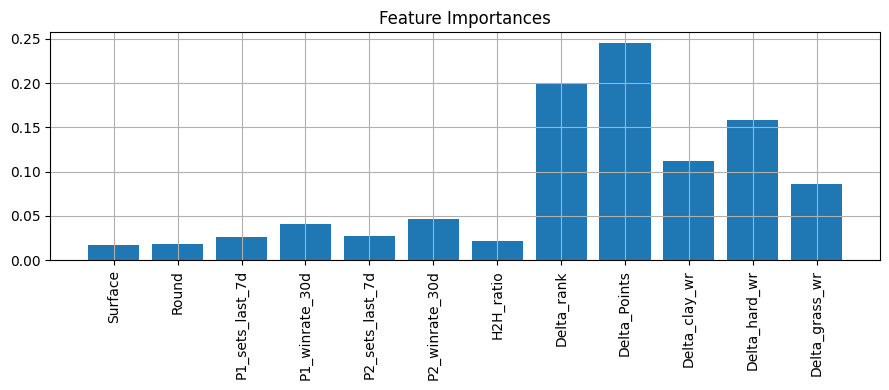

In [12]:
import numpy as np
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt

# use the actual training columns so labels match the matrix
feature_names = np.array(X_train.columns)

# plot feature importances
visualize_feature_importance("Feature Importances", X_train, rf_clf, feature_names)

### GridSearchCV, tuning parameters

In [13]:
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import TimeSeriesSplit

tscv = TimeSeriesSplit(n_splits=5)
# hyper parameter tuning
parameters = {
    "n_estimators": [100, 200],
    "max_depth": [6, 8, 10],
    "min_samples_leaf": [5, 10, 20],
    "criterion": ["gini"],
}

# using log loss is better than accuracy
tuned_model = GridSearchCV(
    rf_clf, parameters, cv=tscv, verbose=0, n_jobs=-1, scoring="neg_log_loss"
)
tuned_model.fit(X_train, y_train)

y_pred = tuned_model.predict(X_test)

print(f"Final Tuned Accuracy: {accuracy_score(y_test, y_pred):.2%}")
print("Best Params:", tuned_model.best_params_)

Final Tuned Accuracy: 64.15%
Best Params: {'criterion': 'gini', 'max_depth': 8, 'min_samples_leaf': 5, 'n_estimators': 200}


### RFECV

In [14]:
from sklearn.feature_selection import RFECV

selector_rfecv = RFECV(
    estimator=tuned_model.best_estimator_,
    step=1,
    cv=tscv,
    scoring="neg_log_loss",
    min_features_to_select=3,
    n_jobs=-1,
)
selector_rfecv.fit(X_train, y_train)
surviving_columns = X_train.columns[selector_rfecv.support_].tolist()

print("RFECV Optimal Number of features:", selector_rfecv.n_features_)
# print("RFECV Selected features:", feature_names[selector_rfecv.support_])

RFECV Optimal Number of features: 12


### RFECV retraining and feature importance visualization

Accuracy: 63.90%


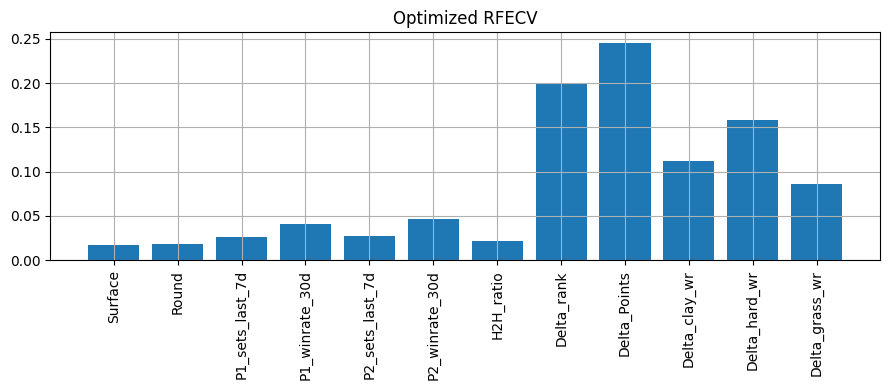

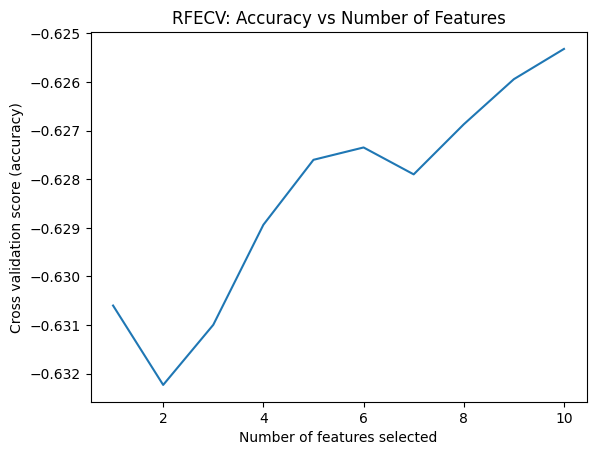

In [15]:
X_train_rfe = selector_rfecv.transform(X_train)
X_test_rfe = selector_rfecv.transform(X_test)

# fit on the selected columns
rf_clf.fit(X_train_rfe, y_train)

# predict on the test set
y_pred = rf_clf.predict(X_test_rfe)
y_prob_rfe = rf_clf.predict_proba(X_test_rfe)[:, 1]

# print(big_misses)

# check the accuracy
print(f"Accuracy: {accuracy_score(y_test, y_pred):.2%}")

feature_names = X_train.columns[selector_rfecv.support_]

# plot the selected features
visualize_feature_importance("Optimized RFECV", X_train_rfe, rf_clf, feature_names)
visualize_feature_line(
    "RFECV: Accuracy vs Number of Features",
    "Number of features selected",
    "Cross validation score (accuracy)",
    selector_rfecv,
)

## XGBoost

In [16]:
from sklearn.model_selection import RandomizedSearchCV
import xgboost as xgb

# xgb baseline

clf_xgb = xgb.XGBClassifier(
    objective="binary:logistic",
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=5,
    enable_categorical=True,
    tree_method="hist",
    random_state=44,
)
clf_xgb.fit(X_train_rfe, y_train)

y_pred_base = clf_xgb.predict(X_test_rfe)
print(f"Accuracy before tuning: {accuracy_score(y_test, y_pred_base):.2%}")

Accuracy before tuning: 61.18%


### XGBoost Hyperparameter Tuning

In [17]:
parameters = {
    "max_depth": [3, 4, 5],
    "learning_rate": [0.01, 0.03],  # slower learning is safer
    "n_estimators": [300, 500],
    "min_child_weight": [10, 15, 20],  # requires a lot of data to justify a split
    "subsample": [0.6, 0.8],  # only use a random 60-80% of rows per tree
    "colsample_bytree": [0.6, 0.8],  # only use a random 60-80% of columns per tree
}

tuned_xgb = RandomizedSearchCV(
    clf_xgb,
    parameters,
    n_iter=15,
    cv=tscv,
    n_jobs=-1,
    verbose=1,
    random_state=42,
)


tuned_xgb.fit(X_train_rfe, y_train)
y_pred_tuned = tuned_xgb.predict(X_test_rfe)
print(f"Accuracy after tuning: {accuracy_score(y_test, y_pred_tuned):.2%}")

Fitting 5 folds for each of 15 candidates, totalling 75 fits
Accuracy after tuning: 64.12%


### XGBoost RFECV (Feature Selection)

In [18]:
selector_xgb_rfecv = RFECV(
    estimator=tuned_xgb.best_estimator_,
    step=1,
    cv=tscv,
    scoring="neg_log_loss",
    min_features_to_select=3,
    n_jobs=-1,
)
selector_xgb_rfecv.fit(X_train_rfe, y_train)

y_pred_rfecv = selector_xgb_rfecv.predict(X_test_rfe)
print(f"Accuracy after XGBoost RFECV: {accuracy_score(y_test, y_pred_rfecv):.2%}")

Accuracy after XGBoost RFECV: 64.12%


## Error Analysis

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt
import math

analysis_df = X_test.copy()
analysis_df["match_id"] = X_test.index  # Add match_id from index
analysis_df["Actual_Winner"] = y_test.values
analysis_df["P1_Win_Prob"] = y_prob_rfe
analysis_df["Predicted_Winner"] = (analysis_df["P1_Win_Prob"] >= 0.5).astype(int)
analysis_df["Is_Correct"] = (
    analysis_df["Predicted_Winner"] == analysis_df["Actual_Winner"]
)


# surviving_columns = X_train.columns[selector_rfecv.support_].tolist()
feature_cols = list(surviving_columns)

# splits every row in test set into two buckets, mean computes avg value of every feature. T is to swap columns and rows
comparison = analysis_df.groupby("Is_Correct")[feature_cols].mean().T

# diff between true and false predictions
comparison["diff"] = comparison[True] - comparison[False]

# scale the diff
comparison["std_diff"] = comparison["diff"] / analysis_df[feature_cols].std()

# print(comparison.sort_values("std_diff", key=abs, ascending=False))

# calculate the error
analysis_df["Error"] = abs(analysis_df["Actual_Winner"] - analysis_df["P1_Win_Prob"])

# 4. Find the most "peculiar" predictions
big_misses = (
    analysis_df.loc[~analysis_df["Is_Correct"]]
    .sort_values(by="Error", ascending=False)
    .head(10)
)

best_hits = (
    analysis_df.loc[analysis_df["Is_Correct"]]
    .sort_values(by="P1_Win_Prob", ascending=False)
    .head(10)
)

In [20]:
try:
    with pd.ExcelWriter("hit_n_miss.xlsx") as writer:
        comparison.to_excel(writer, sheet_name="comp", index=False)
        big_misses.to_excel(writer, sheet_name="big_misses", index=False)
        best_hits.to_excel(writer, sheet_name="best_hits", index=False)
    print("Saved big_misses and best_hits to hit_n_miss.xlsx")
except NameError:
    print("big_misses is not defined. Run the RFECV cell first.")

Saved big_misses and best_hits to hit_n_miss.xlsx


### Visualize Delta_rank and Delta_points accuracy based on intervals, for the report


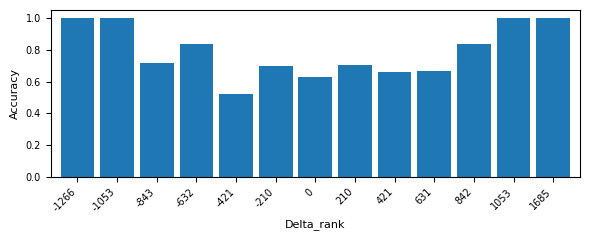

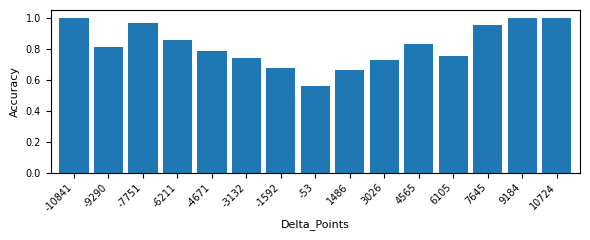

In [21]:
bin_edges = pd.cut(analysis_df["Delta_rank"], bins=15)
result = analysis_df.groupby(bin_edges)["Is_Correct"].agg(["mean", "count"])
result.index = [f"{int(i.mid)}" for i in result.index]

fig, ax = plt.subplots(figsize=(6, 2.5))
result["mean"].plot(kind="bar", ax=ax, width=0.85)
ax.set_ylabel("Accuracy", fontsize=8)
ax.set_xlabel("Delta_rank", fontsize=8)
ax.tick_params(axis="both", labelsize=7)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

bin_edges = pd.cut(analysis_df["Delta_Points"], bins=15)
result = analysis_df.groupby(bin_edges)["Is_Correct"].agg(["mean", "count"])
result.index = [f"{int(i.mid)}" for i in result.index]

fig, ax = plt.subplots(figsize=(6, 2.5))
result["mean"].plot(kind="bar", ax=ax, width=0.85)
ax.set_ylabel("Accuracy", fontsize=8)
ax.set_xlabel("Delta_Points", fontsize=8)
ax.tick_params(axis="both", labelsize=7)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Big Misses vs Best Hits

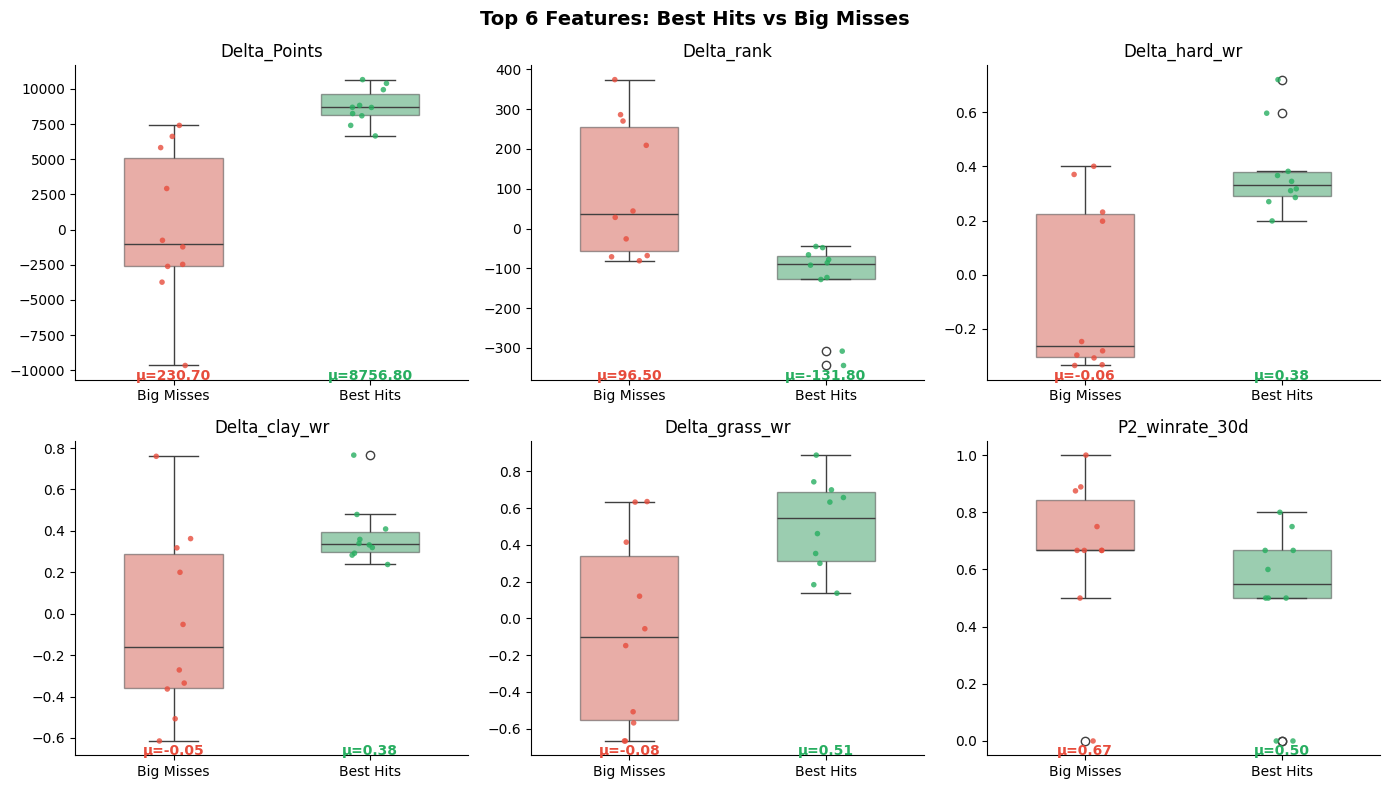

In [22]:
# these plots were AI generated, i left them because i thought they were interesting

feature_names = list(surviving_columns)
top6 = pd.Series(rf_clf.feature_importances_, index=feature_names).nlargest(6).index

big_misses = big_misses.copy()
best_hits = best_hits.copy()
big_misses["Type"] = "Big Misses"
best_hits["Type"] = "Best Hits"
df_combined = pd.concat([big_misses, best_hits], ignore_index=True)

colors = {"Big Misses": "#E74C3C", "Best Hits": "#27AE60"}
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for ax, feat in zip(axes.flat, top6):
    sns.boxplot(
        data=df_combined,
        x="Type",
        y=feat,
        hue="Type",
        ax=ax,
        palette=colors,
        width=0.5,
        boxprops={"alpha": 0.5},
        legend=False,
    )
    sns.stripplot(
        data=df_combined,
        x="Type",
        y=feat,
        hue="Type",
        ax=ax,
        palette=colors,
        jitter=True,
        alpha=0.8,
        size=4,
        legend=False,
    )

    ax.set(title=feat, xlabel="", ylabel="")
    sns.despine(ax=ax)

    means = df_combined.groupby("Type")[feat].mean()
    for i, t in enumerate(["Big Misses", "Best Hits"]):
        ax.text(
            i,
            ax.get_ylim()[0],
            f"μ={means[t]:.2f}",
            ha="center",
            color=colors[t],
            fontweight="bold",
        )

plt.suptitle("Top 6 Features: Best Hits vs Big Misses", fontweight="bold", fontsize=14)
plt.tight_layout()
plt.show()

compare = df_combined.groupby("Type")[feature_names].mean().T
compare["Diff"] = compare["Best Hits"] - compare["Big Misses"]

## AUROC Score

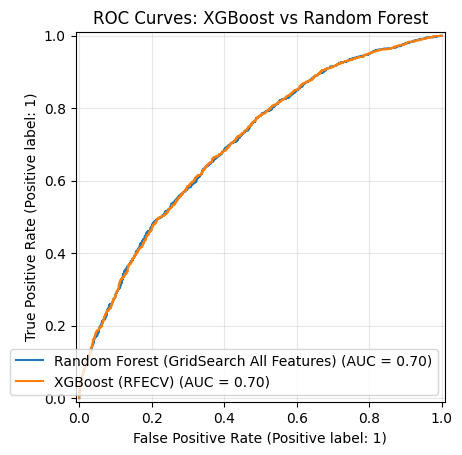

XGBoost AUROC: 0.7038
Random Forest AUROC: 0.7036


In [23]:
y_binary_train = np.where(y_train == 1, 1, 0)
y_binary_valid = np.where(y_train == 1, 1, 0)
y_binary_test = np.where(y_test == 1, 1, 0)

# Retrain model on binary labels
# Plot ROC Curve
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots()
RocCurveDisplay.from_estimator(
    estimator=tuned_model.best_estimator_,
    X=X_test,
    y=y_binary_test,
    ax=ax,
    name="Random Forest (GridSearch All Features)",
)

RocCurveDisplay.from_estimator(
    estimator=selector_xgb_rfecv,
    X=X_test_rfe,
    y=y_binary_test,
    ax=ax,
    name="XGBoost (RFECV)",
)
ax.set_title("ROC Curves: XGBoost vs Random Forest")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

# Compute AUROC Score
from sklearn.metrics import roc_auc_score

auroc_xgb = roc_auc_score(
    y_true=y_binary_test,
    y_score=selector_xgb_rfecv.predict_proba(X_test_rfe)[:, 1],
)
print(f"XGBoost AUROC: {auroc_xgb:.4f}")

# Compute AUROC Score for the GridSearched Random Forest
auroc_rf = roc_auc_score(
    y_true=y_binary_test,
    y_score=selector_rfecv.predict_proba(X_test)[:, 1],
)
print(f"Random Forest AUROC: {auroc_rf:.4f}")

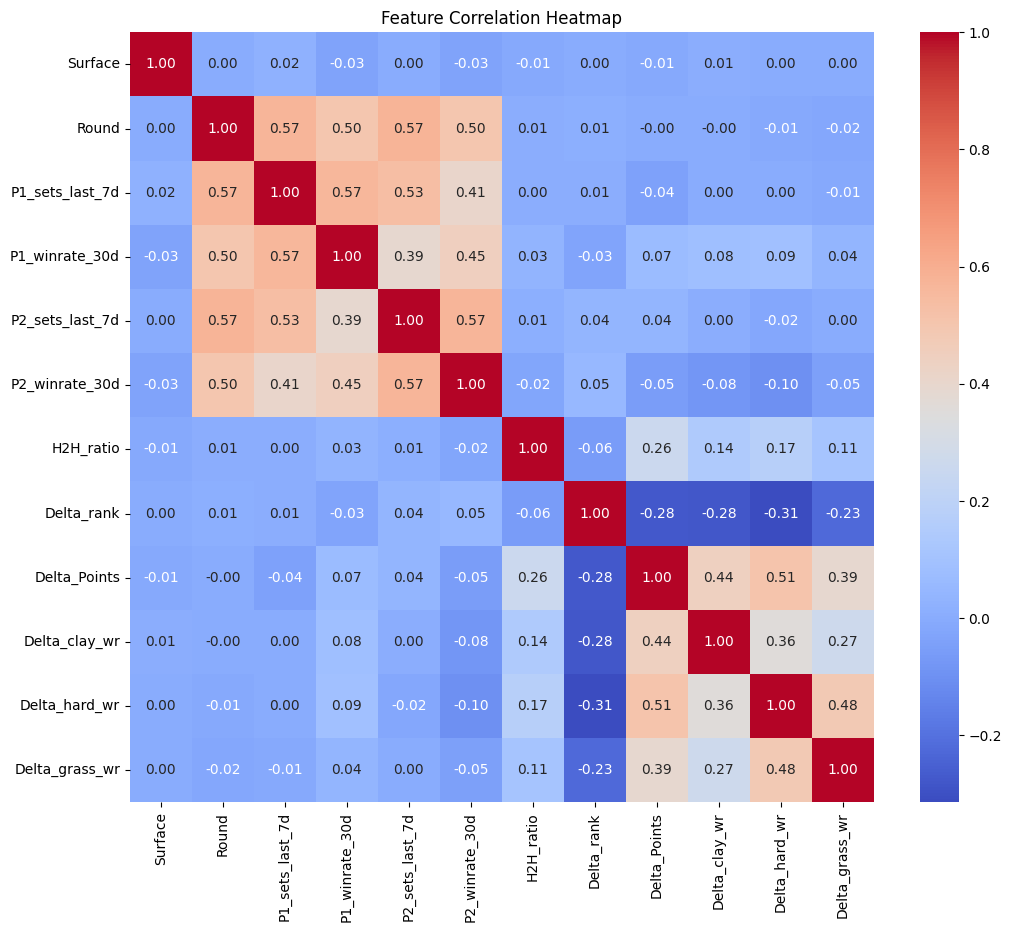

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate correlation matrix for your top 24 features
corr = X_train.corr()

# Plot the heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation Heatmap")
plt.show()

### Confusion Matrix

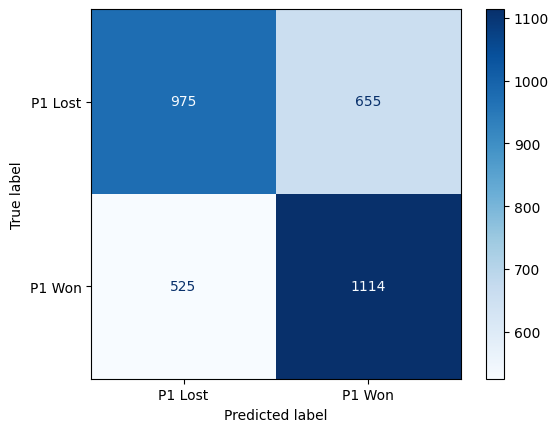

In [25]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Generate the matrix
cm = confusion_matrix(y_test, y_pred)

# Visualize it
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["P1 Lost", "P1 Won"])
disp.plot(cmap="Blues")
plt.show()

### print top 5 features

In [26]:
import pandas as pd

surviving_features = selector_rfecv.get_feature_names_out()

rf_importances = pd.Series(
    selector_rfecv.estimator_.feature_importances_, index=surviving_features
).sort_values(ascending=False)

xgb_importances = pd.Series(
    tuned_xgb.best_estimator_.feature_importances_, index=surviving_features
).sort_values(ascending=False)

print("RF")
print(rf_importances.head(5))
print("\n XGBOOST")
print(xgb_importances.head(5))

RF
Delta_Points      0.278928
Delta_rank        0.211280
Delta_hard_wr     0.161278
Delta_clay_wr     0.098511
Delta_grass_wr    0.075894
dtype: float64

 XGBOOST
Delta_Points      0.249238
Delta_rank        0.214086
Delta_hard_wr     0.114180
P2_winrate_30d    0.059383
Delta_clay_wr     0.056084
dtype: float32
